# Prediksi Keterlambatan Pengiriman E-Commerce

## Latar Belakang
Dari 96.469 pesanan yang dianalisis, 8,1% terlambat sampai ke pelanggan
dibanding estimasi yang dijanjikan. Angka ini terdengar kecil, tapi dalam 23 bulan data itu berarti rata-rata sekitar 340 pelanggan kecewa setiap bulannya tanpa ada peringatan dini bagi tim operasional.

## Rumusan Masalah
Bisakah keterlambatan ini diprediksi sejak pesanan baru dibuat — sebelum
barang dikirim sama sekali — menggunakan informasi yang sudah tersedia saat
itu (metode pembayaran, nilai pesanan, lokasi pelanggan, estimasi pengiriman)?

## Dataset
103.886 baris data transaksi e-commerce dari Brasil, mencakup data pesanan,
pelanggan, dan pembayaran yang awalnya tersebar di beberapa sumber.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/ecommerce_multisource_clean.csv", parse_dates=[
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date"
])

print(df.shape)
print(df["order_status"].value_counts())

(103886, 16)
order_status
delivered      100756
shipped          1166
canceled          664
unavailable       649
invoiced          325
processing        319
created             5
approved            2
Name: count, dtype: int64


## 2. Pembersihan Data Multisumber

Dataset awal memiliki 103.886 baris, namun hanya 99.440 pesanan unik. Setelah ditelusuri, selisih ini terjadi karena satu pesanan bisa dibayar lewat beberapa transaksi terpisah, misalnya kombinasi voucher dan kartu kredit. Akibatnya, satu pesanan tercatat di beberapa baris, semua baris tersebut tetap merujuk ke order yang sama.

Jika tidak diperbaiki, satu pesanan bisa muncul berkali‑kali saat melatih model. Model akan menghasilkan beberapa prediksi berbeda untuk pesanan yang sama. Akibatnya, hasil analisis menjadi tidak valid.

Data pembayaran diringkas per `order_id`. Nilai pembayaran dijumlahkan, cicilan yang terbanyak diambil, dan metode pembayaran yang pertama tercatat diambil. Setelah itu, data pembayaran digabungkan kembali dengan data pesanan menggunakan `merge`.

In [2]:
ringkasan_bayar = df.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_installments=("payment_installments", "max"),
    payment_type=("payment_type", "first")
).reset_index()

kolom_order = ["order_id", "customer_id", "order_status", "order_purchase_timestamp",
               "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date",
               "order_estimated_delivery_date", "customer_unique_id", "customer_zip_code_prefix", 
               "customer_city", "customer_state"]
df_order_bersih = df[kolom_order].drop_duplicates(subset="order_id")

print("Jumlah baris order unik:", len(df_order_bersih))

df_bersih = pd.merge(df_order_bersih, ringkasan_bayar, on="order_id", how="left")

print("Jumlah baris setelah digabung:", len(df_bersih))
print("Apakah order_id masih unik?", df_bersih["order_id"].nunique() == len(df_bersih))

Jumlah baris order unik: 99440
Jumlah baris setelah digabung: 99440
Apakah order_id masih unik? True


## 3. Pencegahan Kebocoran Data (Data Leakage)

Target `telat` dihitung dari selisih antara `order_delivered_customer_date` (tanggal barang sampai) dan `order_estimated_delivery_date` (tanggal estimasi). Tapi ada satu masalah: kolom `order_delivered_customer_date` baru bisa diketahui setelah barang benar-benar sampai ke tangan pelanggan. Artinya, informasi ini tidak tersedia saat pesanan baru dibuat.

Karena itu, fitur turunan seperti `lama_pengiriman_hari` (durasi pengiriman sebenarnya) **dihindari sebagai fitur dalam model**, meskipun secara statistik sangat terkait dengan target. Penggunaan fitur ini akan menyebabkan *data leakage*. Kalau model memakai informasi yang sebenarnya tidak tersedia pada saat prediksi, hasilnya akan terlihat sangat bagus saat diuji. Tapi pada kenyataannya, model tidak akan bisa digunakan karena informasi yang dibutuhkan belum ada.

Fitur yang dipakai tetap terbatas pada data yang sudah tersedia saat pelanggan menyelesaikan pembelian. Ini termasuk metode pembayaran, nilai pesanan, estimasi pengiriman, lokasi pelanggan, serta waktu pembelian (hari dan bulan). Semua informasi ini bisa diketahui sebelum pesanan diproses, sehingga aman digunakan untuk membangun model.

In [3]:
df_delivered = df_bersih[df_bersih["order_status"] == "delivered"].copy()
df_delivered = df_delivered.dropna(subset=["order_delivered_customer_date"])

df_delivered["telat"] = (
    df_delivered["order_delivered_customer_date"] > df_delivered["order_estimated_delivery_date"]
).astype(int)

df_delivered["order_purchase_timestamp"] = pd.to_datetime(df_delivered["order_purchase_timestamp"])
df_delivered["order_delivered_customer_date"] = pd.to_datetime(df_delivered["order_delivered_customer_date"])
df_delivered["order_estimated_delivery_date"] = pd.to_datetime(df_delivered["order_estimated_delivery_date"])

print("Jumlah baris:", len(df_delivered))
print(df_delivered["telat"].value_counts(normalize=True))

Jumlah baris: 96469
telat
0    0.918886
1    0.081114
Name: proportion, dtype: float64


## 4. Feature Engineering

Dari kolom tanggal pembelian, dibuat tiga fitur baru yang sudah tersedia sejak pesanan dibuat:

- `estimasi_hari` — jumlah hari yang dijanjikan untuk pengiriman

- `hari_dalam_minggu_beli` — hari pembelian dilakukan (Senin-Minggu)

- `bulan_beli` — bulan pembelian dilakukan

Kolom `customer_city` memiliki 4.085 nilai unik. Jika langsung diubah menjadi variabel kategori, akan menghasilkan ribuan kolom baru. Ini membuat model sulit menangkap pola yang bermakna. Untuk itu, kota dengan jumlah pesanan kurang dari 100 digabung menjadi satu kategori bernama "Lainnya". Dengan cara ini, jumlah kategori berkurang menjadi 136, tetap mempertahankan informasi dari kota-kota besar.

Semua fitur kategori seperti metode pembayaran, provinsi, dan kota kemudian diubah menjadi variabel numerik menggunakan one-hot encoding sebelum digunakan dalam model.

In [4]:
df_delivered["estimasi_hari"] = (
    df_delivered["order_estimated_delivery_date"] - df_delivered["order_purchase_timestamp"]
).dt.days

df_delivered["hari_dalam_minggu_beli"] = df_delivered["order_purchase_timestamp"].dt.dayofweek
df_delivered["bulan_beli"] = df_delivered["order_purchase_timestamp"].dt.month

jumlah_per_kota = df_delivered["customer_city"].value_counts()
kota_jarang = jumlah_per_kota[jumlah_per_kota < 100].index
df_delivered["kota_ringkas"] = df_delivered["customer_city"].replace(kota_jarang, "Lainnya")

print(df_delivered[["estimasi_hari", "hari_dalam_minggu_beli", "bulan_beli", "telat"]].head(10))

    estimasi_hari  hari_dalam_minggu_beli  bulan_beli  telat
0              15                       0          10      0
1              19                       1           7      0
2              26                       2           8      0
3              26                       5          11      0
4              12                       1           2      0
5              22                       6           7      0
7              21                       1           5      0
8              41                       0           1      0
9              24                       5           7      0
10             21                       1           5      0


In [5]:
kolom_dipakai = [
    "telat",
    "payment_type", "payment_installments", "payment_value",
    "customer_state", "kota_ringkas",
    "estimasi_hari", "hari_dalam_minggu_beli", "bulan_beli"
]

df_model = df_delivered[kolom_dipakai].copy()
df_model = pd.get_dummies(df_model, columns=["payment_type", "customer_state", "kota_ringkas"], drop_first=True)

print("Jumlah baris:", df_model.shape[0])
print("Jumlah kolom:", df_model.shape[1])

Jumlah baris: 96469
Jumlah kolom: 170


## 5. Modeling & Evaluasi

### Model Dasar: Temuan Kritis

Kami melatih model Random Forest pertama dan melihat akurasi 91,9%. Angka ini terlihat bagus, tapi ternyata menyesatkan. Setelah kami cek lebih detail, model nyaris tidak menandai pesanan yang benar-benar terlambat. Recall 0%. Akurasi tinggi hanya karena mayoritas data tidak terlambat: 91,9% pesanan memang tidak terlambat. Model hanya menjawab “tidak terlambat” dan tetap terlihat akurat.

### Perbaikan

Untuk memperbaiki masalah ini, kami melakukan dua langkah:

1. **`class_weight="balanced"`** – memberi bobot lebih besar pada kasus keterlambatan saat melatih model, sehingga model tidak mengabaikannya.

2. **Threshold tuning** – menurunkan ambang batas keputusan dari 0,5 menjadi 0,4. Saya pilih angka ini karena menghasilkan keseimbangan terbaik antara jumlah keterlambatan yang terdeteksi dan jumlah peringatan palsu yang masih wajar ditindaklanjuti oleh tim operasional.

### Hasil Akhir

| Metrik | Model Dasar | Model Setelah Perbaikan |

|---|---|---|

| Recall (Telat) | 0% | 76% |

| Precision (Telat) | 50%* | 15% |

| ROC-AUC | - | 0,767 |

*Precision 50% pada model dasar tidak bermakna, karena dihitung dari segelintir pesanan yang ditandai.

Validasi dengan `RandomizedSearchCV` menunjukkan parameter yang dipilih sudah mendekati optimal. ROC-AUC 0,767 sebelum dan sesudah tuning, jadi model cukup stabil.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

X = df_model.drop("telat", axis=1)
y = df_model["telat"]

print("Baseline (tebak asal-asalan):", y.value_counts(normalize=True).max())

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

model_balanced = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight="balanced", 
    random_state=42
)
model_balanced.fit(X_tr, y_tr)

proba_balanced = model_balanced.predict_proba(X_te)[:, 1]
pred_treshold_04 = (proba_balanced >= 0.4).astype(int)

print(classification_report(y_te, pred_treshold_04, target_names=["Tidak telat", "Telat"]))

Baseline (tebak asal-asalan): 0.9188858597062268
              precision    recall  f1-score   support

 Tidak telat       0.97      0.64      0.77     17773
       Telat       0.15      0.76      0.25      1521

    accuracy                           0.65     19294
   macro avg       0.56      0.70      0.51     19294
weighted avg       0.90      0.65      0.73     19294



In [7]:
print(df_delivered.columns.tolist())
print()
print(df_delivered[["payment_type", "payment_installments", "customer_state"]].head())

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'payment_value', 'payment_installments', 'payment_type', 'telat', 'estimasi_hari', 'hari_dalam_minggu_beli', 'bulan_beli', 'kota_ringkas']

  payment_type  payment_installments customer_state
0  credit_card                     1             SP
1       boleto                     1             BA
2  credit_card                     3             GO
3  credit_card                     1             RN
4  credit_card                     1             SP


In [8]:
jumlah_per_kota = df_delivered["customer_city"].value_counts()

kota_jarang = jumlah_per_kota[jumlah_per_kota < 100].index
df_delivered["kota_ringkas"] = df_delivered["customer_city"].replace(kota_jarang, "Lainnya")

print("Jumlah kategori sebelum diringkas:", df_delivered["customer_city"].nunique())
print("Jumlah kategori setelah diringkas:", df_delivered["kota_ringkas"].nunique())
print()
print(df_delivered["kota_ringkas"].value_counts().head(15))

Jumlah kategori sebelum diringkas: 4085
Jumlah kategori setelah diringkas: 136

kota_ringkas
Lainnya                  32203
sao paulo                15045
rio de janeiro            6601
belo horizonte            2697
brasilia                  2071
curitiba                  1489
campinas                  1406
porto alegre              1341
salvador                  1188
guarulhos                 1143
sao bernardo do campo      911
niteroi                    825
santo andre                778
osasco                     724
santos                     700
Name: count, dtype: int64


In [9]:
jumlah_per_kota = df_delivered["customer_city"].value_counts()
kota_jarang_500 = jumlah_per_kota[jumlah_per_kota < 500].index
df_delivered["kota_ringkas_500"] = df_delivered["customer_city"].replace(kota_jarang_500, "Lainnya")

print("Jumlah kategori dengan batas <500:", df_delivered["kota_ringkas_500"].nunique())
print(df_delivered["kota_ringkas_500"].value_counts().head(15))

Jumlah kategori dengan batas <500: 22
kota_ringkas_500
Lainnya                  55298
sao paulo                15045
rio de janeiro            6601
belo horizonte            2697
brasilia                  2071
curitiba                  1489
campinas                  1406
porto alegre              1341
salvador                  1188
guarulhos                 1143
sao bernardo do campo      911
niteroi                    825
santo andre                778
osasco                     724
santos                     700
Name: count, dtype: int64


In [10]:
kolom_dipakai = [
    "telat",
    "payment_type", "payment_installments", "payment_value",
    "customer_state", "kota_ringkas",
    "estimasi_hari", "hari_dalam_minggu_beli", "bulan_beli"
]

df_model = df_delivered[kolom_dipakai].copy()

df_model = pd.get_dummies(df_model, columns=["payment_type", "customer_state", "kota_ringkas"], drop_first=True)

print("Jumlah baris:", df_model.shape[0])
print("Jumlah kolom:", df_model.shape[1])
print(df_model.columns.tolist()[:20])

Jumlah baris: 96469
Jumlah kolom: 170
['telat', 'payment_installments', 'payment_value', 'estimasi_hari', 'hari_dalam_minggu_beli', 'bulan_beli', 'payment_type_credit_card', 'payment_type_debit_card', 'payment_type_voucher', 'customer_state_AL', 'customer_state_AM', 'customer_state_AP', 'customer_state_BA', 'customer_state_CE', 'customer_state_DF', 'customer_state_ES', 'customer_state_GO', 'customer_state_MA', 'customer_state_MG', 'customer_state_MS']


In [11]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

X = df_model.drop("telat", axis=1)
y = df_model["telat"]

print("Baseline (tebak asal-asalan):", y.value_counts(normalize=True).max())

model = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)
skor = cross_val_score(model, X, y, cv=5, scoring="accuracy")

print("Nilai tiap ujian:", skor)
print("Rata-rata akurasi:", skor.mean())

Baseline (tebak asal-asalan): 0.9188858597062268
Nilai tiap ujian: [0.9188867  0.91883487 0.91893853 0.9188867  0.9188825 ]
Rata-rata akurasi: 0.9188858596713615


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
model_cek = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)
model_cek.fit(X_tr, y_tr)
pred_cek = model_cek.predict(X_te)

print(classification_report(y_te, pred_cek, target_names=["Tidak telat", "Telat"]))

              precision    recall  f1-score   support

 Tidak telat       0.92      1.00      0.96     17773
       Telat       0.50      0.00      0.00      1521

    accuracy                           0.92     19294
   macro avg       0.71      0.50      0.48     19294
weighted avg       0.89      0.92      0.88     19294



In [13]:
model_balanced = RandomForestClassifier(
    n_estimators=300, 
    min_samples_leaf=5, 
    class_weight="balanced", 
    random_state=42
)
model_balanced.fit(X_tr, y_tr)
pred_balanced = model_balanced.predict(X_te)

print(classification_report(y_te, pred_balanced, target_names=["Tidak telat", "Telat"]))

              precision    recall  f1-score   support

 Tidak telat       0.96      0.80      0.87     17773
       Telat       0.21      0.60      0.31      1521

    accuracy                           0.79     19294
   macro avg       0.58      0.70      0.59     19294
weighted avg       0.90      0.79      0.83     19294



In [14]:
proba_balanced = model_balanced.predict_proba(X_te)[:, 1]

for batas in [0.5, 0.4, 0.3, 0.2]:
    pred_threshold = (proba_balanced >= batas).astype(int)
    print(f"=== Threshold {batas} ===")
    print(classification_report(y_te, pred_threshold, target_names=["Tidak telat", "Telat"]))
    print()

=== Threshold 0.5 ===
              precision    recall  f1-score   support

 Tidak telat       0.96      0.80      0.87     17773
       Telat       0.21      0.60      0.31      1521

    accuracy                           0.79     19294
   macro avg       0.58      0.70      0.59     19294
weighted avg       0.90      0.79      0.83     19294


=== Threshold 0.4 ===
              precision    recall  f1-score   support

 Tidak telat       0.97      0.64      0.77     17773
       Telat       0.15      0.76      0.25      1521

    accuracy                           0.65     19294
   macro avg       0.56      0.70      0.51     19294
weighted avg       0.90      0.65      0.73     19294


=== Threshold 0.3 ===
              precision    recall  f1-score   support

 Tidak telat       0.98      0.38      0.55     17773
       Telat       0.11      0.89      0.20      1521

    accuracy                           0.42     19294
   macro avg       0.54      0.64      0.37     19294
weight

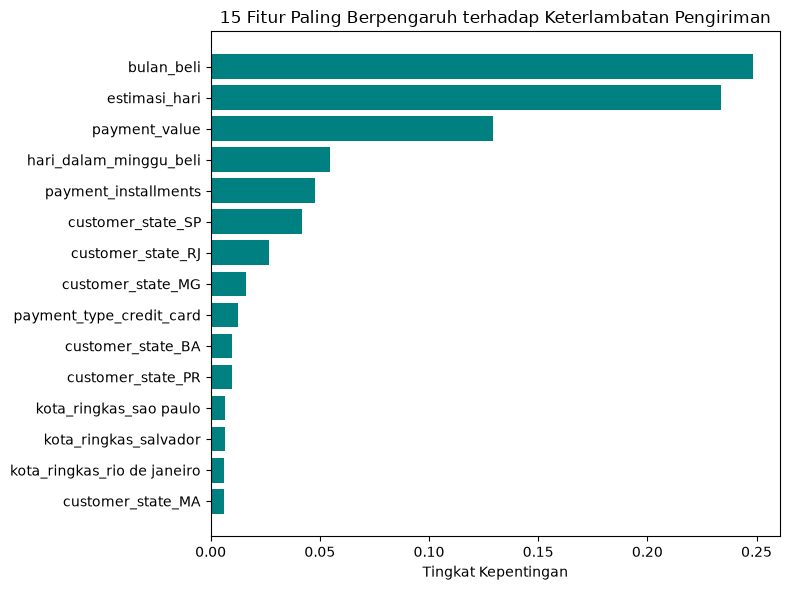

In [15]:
import matplotlib.pyplot as plt

penting = pd.Series(model_balanced.feature_importances_, index=X.columns)
penting_top15 = penting.sort_values(ascending=True).tail(15)

plt.figure(figsize=(8, 6))
plt.barh(penting_top15.index, penting_top15.values, color="teal")
plt.xlabel("Tingkat Kepentingan")
plt.title("15 Fitur Paling Berpengaruh terhadap Keterlambatan Pengiriman")
plt.tight_layout()
plt.show()

In [16]:
tingkat_telat_per_bulan = df_delivered.groupby("bulan_beli")["telat"].mean()
print(tingkat_telat_per_bulan)

bulan_beli
1     0.062284
2     0.134137
3     0.171536
4     0.059554
5     0.066446
6     0.022099
7     0.040786
8     0.075778
9     0.052048
10    0.050601
11    0.143112
12    0.083787
Name: telat, dtype: float64


In [17]:
print(df_delivered.groupby("telat")["payment_value"].describe())

         count        mean         std    min    25%     50%       75%  \
telat                                                                    
0      88644.0  158.718425  217.121966   9.59  61.64  104.62  175.4375   
1       7825.0  172.734414  236.853346  14.29  66.41  112.27  188.1800   

            max  
telat            
0      13664.08  
1       6922.21  


In [18]:
df_delivered["kelompok_harga"] = pd.qcut(df_delivered["payment_value"], q=5, labels=["Termurah", "Murah", "Menengah", "Mahal", "Termahal"])

print(df_delivered.groupby("kelompok_harga")["telat"].mean())

kelompok_harga
Termurah    0.070781
Murah       0.077609
Menengah    0.082517
Mahal       0.085566
Termahal    0.089100
Name: telat, dtype: float64


In [19]:
nama_hari = {0: "Senin", 1: "Selasa", 2: "Rabu", 3: "Kamis", 4: "Jumat", 5: "Sabtu", 6: "Minggu"}
tingkat_telat_hari = df_delivered.groupby("hari_dalam_minggu_beli")["telat"].mean()
tingkat_telat_hari.index = tingkat_telat_hari.index.map(nama_hari)
print(tingkat_telat_hari)

hari_dalam_minggu_beli
Senin     0.090504
Selasa    0.084892
Rabu      0.078015
Kamis     0.075623
Jumat     0.084478
Sabtu     0.075983
Minggu    0.074880
Name: telat, dtype: float64


In [20]:
state_stat = df_delivered.groupby("customer_state").agg(
    tingkat_telat=("telat", "mean"),
    jumlah_pesanan=("telat", "size")
)
state_stat = state_stat.sort_values("tingkat_telat", ascending=False)
print(state_stat)

                tingkat_telat  jumlah_pesanan
customer_state                               
AL                   0.239295             397
MA                   0.196653             717
PI                   0.159664             476
CE                   0.153245            1279
SE                   0.152239             335
BA                   0.140356            3256
RJ                   0.134737           12350
TO                   0.127737             274
PA                   0.123679             946
ES                   0.122306            1995
RR                   0.121951              41
MS                   0.115549             701
PB                   0.110251             517
PE                   0.107972            1593
RN                   0.107595             474
SC                   0.097575            3546
GO                   0.081758            1957
RS                   0.071482            5344
DF                   0.070673            2080
MT                   0.067720     

In [21]:
state_stat_terpercaya = state_stat[state_stat["jumlah_pesanan"] >= 300]
print(state_stat_terpercaya)

                tingkat_telat  jumlah_pesanan
customer_state                               
AL                   0.239295             397
MA                   0.196653             717
PI                   0.159664             476
CE                   0.153245            1279
SE                   0.152239             335
BA                   0.140356            3256
RJ                   0.134737           12350
PA                   0.123679             946
ES                   0.122306            1995
MS                   0.115549             701
PB                   0.110251             517
PE                   0.107972            1593
RN                   0.107595             474
SC                   0.097575            3546
GO                   0.081758            1957
RS                   0.071482            5344
DF                   0.070673            2080
MT                   0.067720             886
SP                   0.058924           40493
MG                   0.056104     

In [22]:
print(df_delivered.groupby("payment_type")["telat"].agg(["mean", "size"]))
print()
print(df_delivered.groupby("payment_installments")["telat"].agg(["mean", "size"]).head(10))

                  mean   size
payment_type                 
boleto        0.088792  19191
credit_card   0.079439  73213
debit_card    0.079568   1483
voucher       0.072424   2582

                          mean   size
payment_installments                 
0                     0.000000      2
1                     0.079298  46811
2                     0.079245  12026
3                     0.082815  10131
4                     0.082046   6862
5                     0.084022   5082
6                     0.080696   3792
7                     0.083387   1559
8                     0.090291   4120
9                     0.100324    618


In [23]:
from xgboost import XGBClassifier

bobot = (y_tr == 0).sum() / (y_tr == 1).sum()

model_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=bobot,
    random_state=42
)
model_xgb.fit(X_tr, y_tr)
pred_xgb = model_xgb.predict(X_te)

print(classification_report(y_te, pred_xgb, target_names=["Tidak telat", "Telat"]))

              precision    recall  f1-score   support

 Tidak telat       0.96      0.75      0.84     17773
       Telat       0.18      0.66      0.29      1521

    accuracy                           0.74     19294
   macro avg       0.57      0.71      0.57     19294
weighted avg       0.90      0.74      0.80     19294



In [24]:
proba_xgb = model_xgb.predict_proba(X_te)[:, 1]

for batas in [0.5, 0.4, 0.3]:
    pred_t = (proba_xgb >= batas).astype(int)
    print(f"=== Threshold {batas} ===")
    print(classification_report(y_te, pred_t, target_names=["Tidak telat", "Telat"]))
    print()

=== Threshold 0.5 ===
              precision    recall  f1-score   support

 Tidak telat       0.96      0.75      0.84     17773
       Telat       0.18      0.66      0.29      1521

    accuracy                           0.74     19294
   macro avg       0.57      0.71      0.57     19294
weighted avg       0.90      0.74      0.80     19294


=== Threshold 0.4 ===
              precision    recall  f1-score   support

 Tidak telat       0.97      0.61      0.75     17773
       Telat       0.14      0.78      0.24      1521

    accuracy                           0.62     19294
   macro avg       0.56      0.69      0.50     19294
weighted avg       0.90      0.62      0.71     19294


=== Threshold 0.3 ===
              precision    recall  f1-score   support

 Tidak telat       0.98      0.41      0.58     17773
       Telat       0.11      0.89      0.20      1521

    accuracy                           0.45     19294
   macro avg       0.55      0.65      0.39     19294
weight

In [25]:
import joblib

model_final = RandomForestClassifier(
    n_estimators=300, 
    min_samples_leaf=5, 
    class_weight="balanced", 
    random_state=42
)
model_final.fit(X, y)

joblib.dump(model_final, "hasil/model_telat.pkl")
print("Model final tersimpan di hasil/model_telat.pkl'")

Model final tersimpan di hasil/model_telat.pkl'


In [26]:
tebakan_final = model_final.predict(X)
keyakinan_final = model_final.predict_proba(X)[:, 1]

hasil_submission = pd.DataFrame({
    "order_id": df_delivered["order_id"].values,
    "prediksi_telat": tebakan_final,
    "keyakinan_telat": keyakinan_final.round(4)
})

print(hasil_submission.head(10))
print("\nJumlah baris:", len(hasil_submission))

hasil_submission.to_csv("hasil/submission_keterlambatan.csv", index=False)
print("File tersimpan di hasil/submission_keterlambatan.csv")

                           order_id  prediksi_telat  keyakinan_telat
0  e481f51cbdc54678b7cc49136f2d6af7               0           0.3552
1  53cdb2fc8bc7dce0b6741e2150273451               0           0.4092
2  47770eb9100c2d0c44946d9cf07ec65d               0           0.3482
3  949d5b44dbf5de918fe9c16f97b45f8a               1           0.5911
4  ad21c59c0840e6cb83a9ceb5573f8159               0           0.3544
5  a4591c265e18cb1dcee52889e2d8acc3               0           0.1785
6  6514b8ad8028c9f2cc2374ded245783f               1           0.5356
7  76c6e866289321a7c93b82b54852dc33               0           0.2821
8  e69bfb5eb88e0ed6a785585b27e16dbf               0           0.1864
9  e6ce16cb79ec1d90b1da9085a6118aeb               0           0.4050

Jumlah baris: 96469
File tersimpan di hasil/submission_keterlambatan.csv


In [27]:
print(df_delivered[df_delivered["order_id"] == "e481f51cbdc54678b7cc49136f2d6af7"])

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   

  order_estimated_delivery_date                customer_unique_id  \
0                    2017-10-18  7c396fd4830fd04220f754e42b4e5bff   

   customer_zip_code_prefix  ... payment_value payment_installments  \
0                      3149  ...         38.71                    1   

   payment_type  telat estimasi_hari  hari_dalam_minggu_beli  bulan_beli  \
0   credit_card      0            15                       0          10   

   kota_ringkas  kota_ringkas_500 kelompok_harga  
0     sao paulo         sao paulo       Termurah  

[1 rows x 22 columns]


In [28]:
cek = hasil_submission[hasil_submission["order_id"] == "e481f51cbdc54678b7cc49136f2d6af7"]
print(cek)
print("\nApakah order_id di submission final semuanya unik?", hasil_submission["order_id"].nunique() == len(hasil_submission))

                           order_id  prediksi_telat  keyakinan_telat
0  e481f51cbdc54678b7cc49136f2d6af7               0           0.3552

Apakah order_id di submission final semuanya unik? True


## 6. Insight Bisnis

Selain membuat model prediksi, data mengungkap tiga pola penting yang bisa menjadi dasar rekomendasi operasional.

### Pengaruh Karnaval Brasil

Tingkat keterlambatan naik tajam pada bulan Februari, 13,4%, dan Maret, 17,2%, jauh di atas rata-rata bulan lain yang di bawah 8%. Awalnya kami curiga musim belanja akhir tahun (November-Desember) yang menyebabkan masalah, tapi data membalikkan dugaan: Desember hanya 8,4%. Setelah ditelusuri, periode Februari-Maret ternyata bersamaan dengan Karnaval Brasil, perayaan nasional di mana aktivitas logistik dan bisnis melambat cukup signifikan selama hampir seminggu.

**Rekomendasi:** Tambahkan stok buffer atau sesuaikan estimasi pengiriman menjelang periode Karnaval Brasil setiap tahunnya.

### Efek Penumpukan Hari Senin

Pesanan yang dibuat pada Hari Senin memiliki tingkat keterlambatan tertinggi, 9,1%, tidak seperti pesanan yang dibuat di akhir pekan seperti yang kami duga awalnya. Pola ini kemungkinan terjadi karena pesanan yang masuk selama Sabtu-Minggu—ketika kapasitas gudang berkurang—baru diproses pada Hari Senin. Akibatnya, tim gudang menghadapi beban kerja yang menumpuk.

**Rekomendasi:** Tambahkan kapasitas staf gudang pada Hari Senin pagi, atau bagi sebagian proses ke akhir pekan.

### Pola Geografis

Lima provinsi dengan tingkat keterlambatan tertinggi—Alagoas 23,9%, Maranhão 19,7%, Piauí 16,0%, Ceará 15,3%, Sergipe 15,2%—semua berada di wilayah Timur Laut Brasil. Wilayah ini cukup jauh dari pusat distribusi utama di wilayah Tenggara. Sebaliknya, provinsi dengan tingkat keterlambatan terendah—Paraná, Minas Gerais, São Paulo—berada di wilayah Tenggara dan Selatan yang memiliki infrastruktur lebih maju.

**Rekomendasi:** Evaluasi kemitraan logistik atau tambahkan titik distribusi di wilayah Timur Laut.

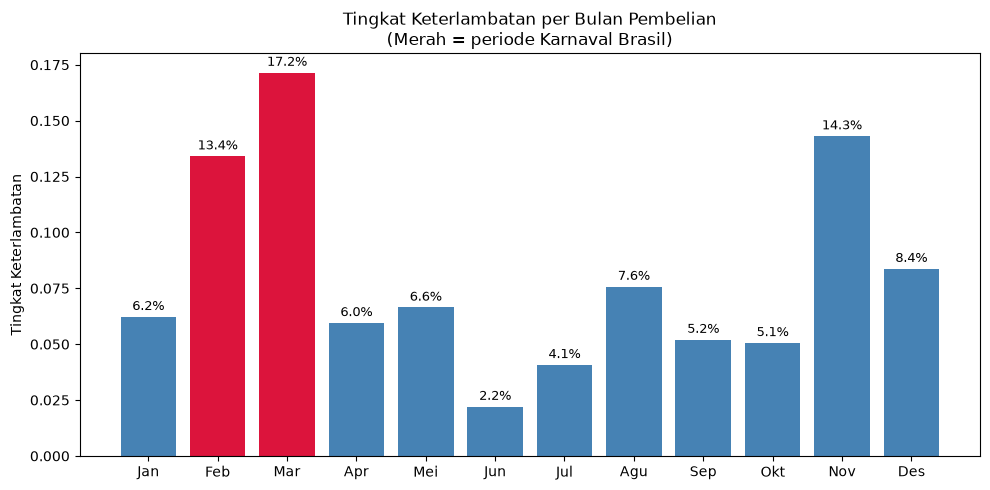

In [29]:
import matplotlib.pyplot as plt

nama_bulan = {1:"Jan",2:"Feb",3:"Mar",4:"Apr",5:"Mei",6:"Jun",
              7:"Jul",8:"Agu",9:"Sep",10:"Okt",11:"Nov",12:"Des"}

tingkat_per_bulan = df_delivered.groupby("bulan_beli")["telat"].mean().sort_index()
tingkat_per_bulan.index = tingkat_per_bulan.index.map(nama_bulan)

warna = ["crimson" if b in ["Feb", "Mar"] else "steelblue" for b in tingkat_per_bulan.index]

plt.figure(figsize=(10, 5))
plt.bar(tingkat_per_bulan.index, tingkat_per_bulan.values, color=warna)
plt.ylabel("Tingkat Keterlambatan")
plt.title("Tingkat Keterlambatan per Bulan Pembelian\n(Merah = periode Karnaval Brasil)")
for i, v in enumerate(tingkat_per_bulan.values):
    plt.text(i, v + 0.003, f"{v:.1%}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("hasil/grafik_bulan.png", dpi=150)
plt.show()

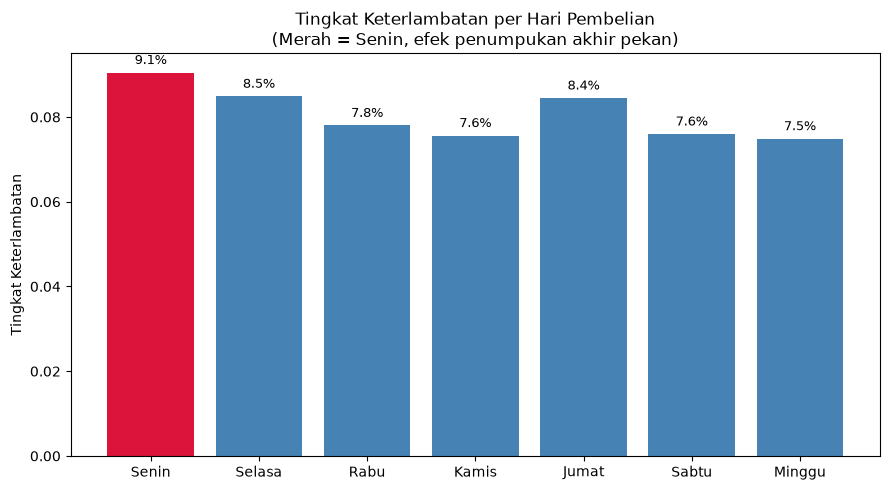

In [30]:
nama_hari = {0:"Senin", 1:"Selasa", 2:"Rabu", 3:"Kamis", 4:"Jumat", 5:"Sabtu", 6:"Minggu"}
tingkat_per_hari = df_delivered.groupby("hari_dalam_minggu_beli")["telat"].mean()
tingkat_per_hari.index = tingkat_per_hari.index.map(nama_hari)

warna_hari = ["crimson" if h == "Senin" else "steelblue" for h in tingkat_per_hari.index]

plt.figure(figsize=(9, 5))
plt.bar(tingkat_per_hari.index, tingkat_per_hari.values, color=warna_hari)
plt.ylabel("Tingkat Keterlambatan")
plt.title("Tingkat Keterlambatan per Hari Pembelian\n(Merah = Senin, efek penumpukan akhir pekan)")
for i, v in enumerate(tingkat_per_hari.values):
    plt.text(i, v + 0.002, f"{v:.1%}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("hasil/grafik_hari.png", dpi=150)
plt.show()

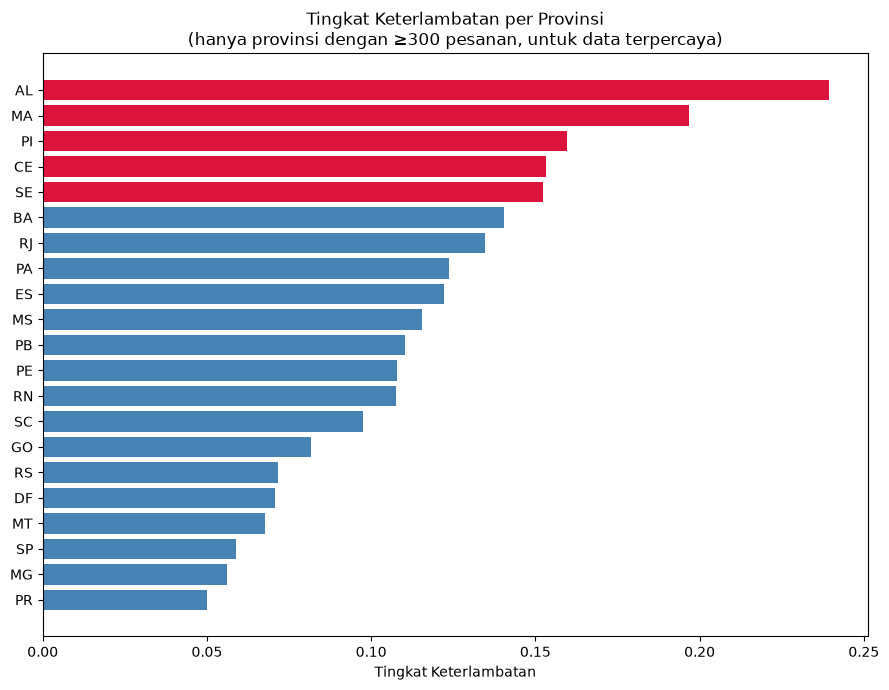

In [31]:
state_stat = df_delivered.groupby("customer_state").agg(
    tingkat_telat=("telat", "mean"),
    jumlah_pesanan=("telat", "size")
)
state_stat_terpercaya = state_stat[state_stat["jumlah_pesanan"] >= 300].sort_values("tingkat_telat", ascending=False)

plt.figure(figsize=(9, 7))
warna_provinsi = ["crimson" if v > 0.15 else "steelblue" for v in state_stat_terpercaya["tingkat_telat"]]
plt.barh(state_stat_terpercaya.index[::-1], state_stat_terpercaya["tingkat_telat"][::-1], color=warna_provinsi[::-1])
plt.xlabel("Tingkat Keterlambatan")
plt.title("Tingkat Keterlambatan per Provinsi\n(hanya provinsi dengan ≥300 pesanan, untuk data terpercaya)")
plt.tight_layout()
plt.savefig("hasil/grafik_provinsi.png", dpi=150)
plt.show()

ROC-AUC: 0.7665425467709831


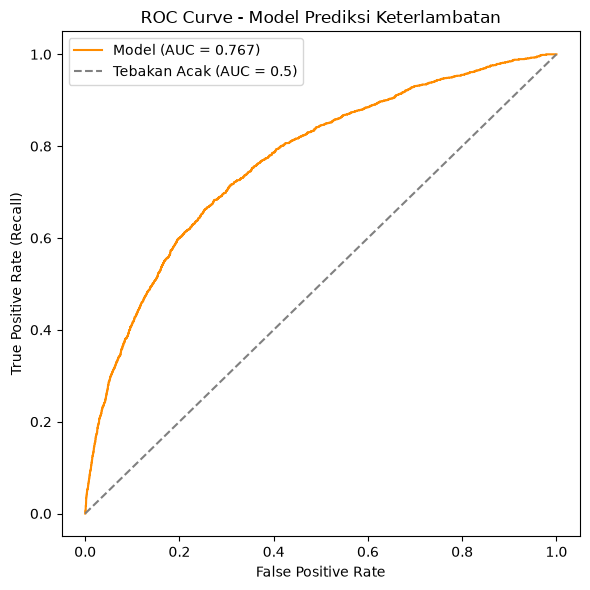

In [32]:
from sklearn.metrics import roc_auc_score, roc_curve

skor_auc = roc_auc_score(y_te, proba_balanced)
print("ROC-AUC:", skor_auc)

fpr, tpr, _ = roc_curve(y_te, proba_balanced)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="darkorange", label=f"Model (AUC = {skor_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Tebakan Acak (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Model Prediksi Keterlambatan")
plt.legend()
plt.tight_layout()
plt.savefig("hasil/grafik_roc.png", dpi=150)
plt.show()

In [33]:
from sklearn.model_selection import RandomizedSearchCV

parameter_dicoba = {
    "n_estimators": [200, 300, 500],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [2, 5, 10],
}

pencarian = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42),
    param_distributions=parameter_dicoba,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1
)

pencarian.fit(X_tr, y_tr)

print("Parameter terbaik:", pencarian.best_params_)
print("ROC-AUC terbaik (saat latihan):", pencarian.best_score_)

Parameter terbaik: {'n_estimators': 200, 'min_samples_leaf': 5, 'max_depth': None}
ROC-AUC terbaik (saat latihan): 0.7598991673115226


In [34]:
model_gridsearch = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    max_depth=None,
    class_weight="balanced",
    random_state=42
)
model_gridsearch.fit(X_tr, y_tr)

proba_gridsearch = model_gridsearch.predict_proba(X_te)[:, 1]
print("ROC-AUC (model lama, n_estimators=300):", skor_auc)
print("ROC-AUC (model GridSearch, n_estimators=200):", roc_auc_score(y_te, proba_gridsearch))

ROC-AUC (model lama, n_estimators=300): 0.7665425467709831
ROC-AUC (model GridSearch, n_estimators=200): 0.7668899404288866


In [35]:
perbandingan = pd.DataFrame({
    "Model": ["Dasar (tanpa balance)", "Balanced", "Balanced + threshold 0.4", "GridSearch tuned"],
    "Recall": [0.00, 0.59, 0.76, 0.76],
    "ROC-AUC": [None, 0.767, 0.767, 0.767]
})
print(perbandingan)

                      Model  Recall  ROC-AUC
0     Dasar (tanpa balance)    0.00      NaN
1                  Balanced    0.59    0.767
2  Balanced + threshold 0.4    0.76    0.767
3          GridSearch tuned    0.76    0.767


In [36]:
import joblib
joblib.dump(X.columns.tolist(), "hasil/kolom_model.pkl")
print("Daftar kolom tersimpan:", len(X.columns))

Daftar kolom tersimpan: 169


In [37]:
daftar_provinsi = sorted(df_delivered["customer_state"].unique().tolist())
daftar_payment = sorted(df_delivered["payment_type"].unique().tolist())

joblib.dump(daftar_provinsi, "hasil/daftar_provinsi.pkl")
joblib.dump(daftar_payment, "hasil/daftar_payment.pkl")
print("Provinsi:", daftar_provinsi)
print("Metode bayar:", daftar_payment)

Provinsi: ['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']
Metode bayar: ['boleto', 'credit_card', 'debit_card', 'voucher']
